# Экзаменационная задача №1. Оценка экономической эффективности внедрения облачной CRM

- **Курс:** Экономика информатизации, лекция №1 «Экономические основы информатизации»
- **Студент:** Солдатов Сергей Юрьевич
- **Группа:** ПИ4-1
- **Дата:** 2026-11-17

In [1]:
# ============================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №01: ОЦЕНКА ЭКОНОМИЧЕСКОЙ ЭФФЕКТИВНОСТИ
#                             ВНЕДРЕНИЯ ОБЛАЧНОЙ CRM
# ============================================================================
# Дата: 2026-11-17
# Студент: Солдатов Сергей Юрьевич
# Группа: ПИ4-1
# ============================================================================

# Библиотеки: numpy и pandas — расчеты и таблицы, matplotlib — графики
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MLN = 1_000_000  # рублей в миллионе


def fmt(value, digits=0):
    """Число в привычной записи: 1 296 000 или 11,58."""
    value = round(value, digits) + 0          # «+ 0» убирает минус у нуля
    text = f"{value:,.{digits}f}"
    return text.replace(",", " ").replace(".", ",").replace("-", "−")


def pct(value, digits=0):
    """Доля в процентах: 0.06 -> 6%."""
    return fmt(value * 100, digits) + "%"


# Числа в таблицах pandas показываем в том же формате, с двумя знаками
pd.options.display.float_format = lambda value: fmt(value, 2)

# Единый вид графиков: светлый фон, сетка, без верхней и правой рамки
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

# Цвета: синий — выгоды, оранжевый — затраты, зеленый и серый — вспомогательные
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"

# Графики сохраняем в reports/figures (ноутбук запускается из папки notebooks)
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

## Экономическая постановка задачи

**Проблема.** Компания «ТехноПром» решает, покупать ли подписку на облачную CRM для отдела продаж из 15 менеджеров.
Затраты на CRM видны сразу (лицензии, время на обучение), а выгоды приходят позже и заранее точно не известны.

**Актуальность.** Главная мысль лекции №1: информатизация не дает прибыль автоматически (парадокс производительности
Солоу). Поэтому решение о покупке ИТ-системы нужно обосновывать расчетом, а не верой в технологию.

**Цель.** Определить, выгодно ли внедрение CRM на горизонте 3 лет.

**Задачи:**
1. посчитать прямой эффект: экономию на оплате труда и дополнительный доход от роста продаж;
2. посчитать затраты: лицензии и потери на время обучения;
3. найти прирост чистой прибыли по годам, NPV, срок окупаемости и ROI;
4. проверить, насколько вывод устойчив, и разобрать нематериальные эффекты и парадокс Солоу.

## 1. Исходные данные

### 1.1. Параметры проекта

Значения взяты из условия задачи (методичка, лекция №1, раздел «Экзаменационная задача»). Исключение — ставка
страховых взносов: в условии ее нет, это справочное значение (раздел 1.2).

In [2]:
# Все исходные данные лежат в одном словаре: меняем значение здесь — пересчитывается всё
BASE = {
    "managers": 15,           # менеджеров в отделе продаж, чел.
    "salary": 120_000,        # средняя зарплата менеджера, руб./мес.
    "routine_share": 0.30,    # доля рабочего времени на рутину (без CRM)
    "routine_saving": 0.20,   # какую часть рутинного времени экономит CRM
    "sales_growth": 0.08,     # рост продаж после внедрения, в год
    "turnover": 72_000_000,   # годовой оборот отдела продаж, руб.
    "license": 24_000,        # цена CRM на одного пользователя, руб./год
    "adaptation_months": 1,   # потеря времени на обучение, мес.
    "years": 3,               # горизонт оценки, лет
    "rate": 0.12,             # ставка дисконтирования
    "tax": 0.20,              # налог на прибыль
    "insurance": 0.30,        # страховые взносы с зарплаты — справочное значение, не из условия
}

# Таблица строится из словаря, поэтому всегда совпадает с расчетом
source_table = pd.DataFrame(
    [
        ("Количество менеджеров, чел.", fmt(BASE["managers"])),
        ("Средняя зарплата менеджера, руб./мес.", fmt(BASE["salary"])),
        ("Доля времени на рутинные операции (без CRM)", pct(BASE["routine_share"])),
        ("Экономия времени на рутинных операциях с CRM", pct(BASE["routine_saving"])),
        ("Рост продаж после внедрения, в год", pct(BASE["sales_growth"])),
        ("Годовой оборот отдела продаж, руб.", fmt(BASE["turnover"])),
        ("Стоимость CRM на пользователя, руб./год", fmt(BASE["license"])),
        ("Потеря времени на адаптацию, мес.", fmt(BASE["adaptation_months"])),
        ("Горизонт оценки, лет", fmt(BASE["years"])),
        ("Ставка дисконтирования", pct(BASE["rate"])),
        ("Налог на прибыль", pct(BASE["tax"])),
        ("Страховые взносы с зарплаты (справочное значение, не из условия)",
         pct(BASE["insurance"])),
    ],
    columns=["Параметр", "Значение"],
)
display(source_table)

,Параметр,Значение
0,"Количество менеджеров, чел.",15
1,"Средняя зарплата менеджера, руб./мес.",120 000
2,Доля времени на рутинные операции (без CRM),30%
3,Экономия времени на рутинных операциях с CRM,20%
4,"Рост продаж после внедрения, в год",8%
5,"Годовой оборот отдела продаж, руб.",72 000 000
6,"Стоимость CRM на пользователя, руб./год",24 000
7,"Потеря времени на адаптацию, мес.",1
8,"Горизонт оценки, лет",3
9,Ставка дисконтирования,12%


### 1.2. Справочные данные

Справочные данные вводятся там, где они нужны: формулы NPV и ROI из лекции №1 — в разделе 2.1, условные значения
для проверки устойчивости — в разделе 2.6.

Ставка страховых взносов — 30%. Это единый тариф страховых взносов, которые работодатель платит с зарплаты
(статья 425 Налогового кодекса РФ). Она нужна, чтобы оценить стоимость рабочего времени в разделах 2.3 и 2.4
(условия У2 и У5).

### 1.3. Дополнительные условия (условия и расчеты)

В условии есть места, которые можно понять по-разному. Каждое такое место разобрано перед тем расчетом, на который
оно влияет: условия У1–У4 — в разделе 2.3, У5–У6 — в разделе 2.4, У7 — в разделе 2.5.

## 2. Расчеты

### 2.1. Математическая модель

**Выгоды в год:**

- экономия на оплате труда: $E_{ФОТ} = n \cdot s \cdot (1 + v) \cdot 12 \cdot d \cdot e$, где $n$ — число менеджеров,
  $s$ — зарплата в месяц, $v$ — ставка страховых взносов, $d$ — доля рутины, $e$ — экономия рутинного времени;
- дополнительный доход: $E_{прод} = R \cdot g$, где $R$ — годовой оборот, $g$ — рост продаж.

**Затраты:** лицензии $C_{лиц} = n \cdot c$ каждый год и потери адаптации $C_{адапт} = n \cdot s \cdot (1 + v) \cdot t$ в первый год
($c$ — цена лицензии, $t$ — месяцы адаптации).

**Прирост чистой прибыли в году $t$** ($T$ — ставка налога на прибыль):

$$\Delta П_t = (E_{ФОТ} + E_{прод} - C_{лиц} - C_{адапт,t}) \cdot (1 - T)$$

**Показатели эффективности** — формулы из лекции №1, п. 6.4 «Методы оценки эффективности ИТ»
($r$ — ставка дисконтирования):

$$NPV = \sum_{t=1}^{3} \frac{\Delta П_t}{(1+r)^t}, \qquad ROI = \frac{Выгоды - Затраты}{Затраты}$$

Простой срок окупаемости — месяц, в котором накопленная чистая прибыль проекта впервые становится неотрицательной.

**Почему эти методы.** NPV учитывает, что деньги будущих лет стоят меньше сегодняшних, поэтому это главный критерий для
многолетнего проекта. ROI показывает отдачу на рубль затрат. Срок окупаемости показывает, как быстро возвращаются
вложения, то есть насколько проект рискован.

### 2.2. Расчетная функция

Весь расчет собран в одной функции. Базовый вариант и сценарии получаются вызовом этой функции с разными аргументами.

In [3]:
def evaluate_crm(p, margin=1.0, time_to_money=1.0, first_year_share=1.0,
                 adaptation_loss=None):
    """Считает денежные потоки проекта CRM по годам и итоговые показатели.

    p                — словарь исходных данных;
    margin           — доля дополнительной выручки, которая становится прибылью;
    time_to_money    — доля сэкономленного времени, которая стала деньгами;
    first_year_share — доля эффекта, полученная в 1-й год (дальше 100%);
    adaptation_loss  — потери адаптации в рублях (None — месячная оплата труда отдела
                       со страховыми взносами).
    """
    years = np.arange(1, p["years"] + 1)

    # Выгоды за год: экономия на оплате труда и доход от роста продаж
    payroll = p["managers"] * p["salary"] * 12                 # ФОТ отдела за год
    labor_cost = payroll * (1 + p["insurance"])                # ФОТ со страховыми взносами
    freed_time = p["routine_share"] * p["routine_saving"]      # доля освобожденного времени
    saving = labor_cost * freed_time * time_to_money
    extra_sales = p["turnover"] * p["sales_growth"]            # прибавка к выручке
    sales_effect = extra_sales * margin                        # ее вклад в прибыль

    # Затраты: лицензии каждый год, потери адаптации только в 1-й год
    licenses = p["managers"] * p["license"]
    if adaptation_loss is None:
        adaptation_loss = labor_cost / 12 * p["adaptation_months"]

    # Раскладываем выгоды и затраты по годам
    share = np.ones(len(years))
    share[0] = first_year_share                                # 1-й год: эффект неполный
    saving_flow = saving * share
    sales_flow = sales_effect * share
    license_flow = np.full(len(years), float(licenses))
    adaptation_flow = np.zeros(len(years))
    adaptation_flow[0] = adaptation_loss

    # От выгод и затрат — к чистой прибыли и дисконтированному потоку
    benefits = saving_flow + sales_flow
    costs = license_flow + adaptation_flow
    profit = benefits - costs                                  # прирост прибыли до налога
    tax = np.maximum(profit, 0) * p["tax"]                     # налог только с прибыли
    net_profit = profit - tax                                  # прирост чистой прибыли
    discount = 1 / (1 + p["rate"]) ** years                    # коэффициенты дисконтирования
    discounted = net_profit * discount

    return {
        "years": years, "payroll": payroll, "labor_cost": labor_cost, "freed_time": freed_time,
        "saving": saving, "extra_sales": extra_sales, "sales_effect": sales_effect,
        "licenses": licenses, "adaptation_loss": adaptation_loss,
        "saving_flow": saving_flow, "sales_flow": sales_flow,
        "license_flow": license_flow, "adaptation_flow": adaptation_flow,
        "benefits": benefits, "costs": costs, "profit": profit, "tax": tax,
        "net_profit": net_profit, "discount": discount, "discounted": discounted,
        "npv": discounted.sum(),
        "roi": (benefits.sum() - costs.sum()) / costs.sum(),   # формула лекции, до налога
        "roi_net": net_profit.sum() / costs.sum(),             # то же по чистой прибыли
    }


# Базовый расчет: по условию задачи и справочной ставке страховых взносов
res = evaluate_crm(BASE)

### 2.3. Прямой эффект от внедрения CRM (задание 1)

Чтобы посчитать эффект, нужно решить, как понимать четыре места условия.

| № | Условия и расчеты | Почему так |
|---|---|---|
| У1 | CRM экономит 20% именно **рутинного** времени. Рутина занимает 30% дня, значит освобождается 30% × 20% = 6% рабочего времени | В условии сказано: «экономия времени на рутинных операциях» |
| У2 | Освобожденное время оцениваем по полной стоимости труда для компании: зарплата плюс страховые взносы 30% | Компания платит за работника не только зарплату, но и страховые взносы. В условии ставка не задана, поэтому взят единый тариф — 30% (статья 425 Налогового кодекса РФ) |
| У3 | Рост продаж 8% — это прибавка к обороту «без CRM» в каждом году, то есть +5,76 млн руб. ежегодно | Осторожное прочтение. Вариант, где рост накапливается, показан в конце расчета ниже |
| У4 | Весь дополнительный доход от продаж идет в доход | Задание просит считать «дополнительный доход», а маржа в условии не задана. Вариант с маржой 20% — в разделе 2.6 |

In [4]:
# Экономия на оплате труда — стоимость рабочего времени, которое освободила CRM
print("Экономия на заработной плате")
print(f"  ФОТ отдела в год: {BASE['managers']} × {fmt(BASE['salary'])} × 12"
      f" = {fmt(res['payroll'])} руб.")
print(f"  ФОТ со страховыми взносами {pct(BASE['insurance'])}: {fmt(res['payroll'])} × "
      f"{fmt(1 + BASE['insurance'], 2)} = {fmt(res['labor_cost'])} руб.")
print(f"  Освобождается времени: {pct(BASE['routine_share'])} × "
      f"{pct(BASE['routine_saving'])} = {pct(res['freed_time'], 1)}")
print(f"  Экономия: {fmt(res['labor_cost'])} × {pct(res['freed_time'], 1)}"
      f" = {fmt(res['saving'])} руб. в год")
print(f"  Это {fmt(BASE['managers'] * res['freed_time'], 1)} ставки менеджера")

# Дополнительный доход от роста продаж
print("\nДополнительный доход от роста продаж")
print(f"  {fmt(BASE['turnover'])} × {pct(BASE['sales_growth'])}"
      f" = {fmt(res['extra_sales'])} руб. в год")

# Итог: сколько CRM приносит за год и какая часть приходится на продажи
effect_year = res["saving"] + res["sales_effect"]
print(f"\nПрямой эффект: {fmt(effect_year)} руб. в год, из них "
      f"{pct(res['sales_effect'] / effect_year)} дает рост продаж")

# Для справки: другая трактовка, когда рост продаж накапливается год к году
compound = [BASE["turnover"] * ((1 + BASE["sales_growth"]) ** t - 1)
            for t in res["years"]]
print("\nЕсли бы рост накапливался год к году, прибавка по годам была бы, млн руб.: "
      + "; ".join(fmt(v / MLN, 2) for v in compound))

Экономия на заработной плате
  ФОТ отдела в год: 15 × 120 000 × 12 = 21 600 000 руб.
  ФОТ со страховыми взносами 30%: 21 600 000 × 1,30 = 28 080 000 руб.
  Освобождается времени: 30% × 20% = 6,0%
  Экономия: 28 080 000 × 6,0% = 1 684 800 руб. в год
  Это 0,9 ставки менеджера

Дополнительный доход от роста продаж
  72 000 000 × 8% = 5 760 000 руб. в год

Прямой эффект: 7 444 800 руб. в год, из них 77% дает рост продаж

Если бы рост накапливался год к году, прибавка по годам была бы, млн руб.: 5,76; 11,98; 18,70


### 2.4. Затраты на внедрение (задание 2)

Для затрат нужны еще два условия.

| № | Условия и расчеты | Почему так |
|---|---|---|
| У5 | Потери адаптации равны месячной оплате труда отдела со страховыми взносами (2,34 млн руб.) и относятся к 1-му году. Эффект от CRM при этом считаем за все 12 месяцев | В условии говорится о потере **времени** на 1 месяц, а время мы оцениваем по стоимости труда (как в У2). Вариант «потерян месячный оборот» — в разделе 2.6 |
| У6 | Капитальных затрат нет, лицензии оплачиваются в начале каждого года | Облачная модель (SaaS): подписка вместо покупки |

In [5]:
# Лицензии: платим за каждого менеджера каждый год
licenses_total = res["license_flow"].sum()
print(f"Лицензии в год: {BASE['managers']} × {fmt(BASE['license'])}"
      f" = {fmt(res['licenses'])} руб.")
print(f"Лицензии за весь срок ({BASE['years']} г.): {fmt(licenses_total)} руб.")

# Потери адаптации: месяц работы отдела, оцененный по зарплате со страховыми взносами
print(f"Потери адаптации: {BASE['managers']} × {fmt(BASE['salary'])} × "
      f"{fmt(1 + BASE['insurance'], 2)} × {BASE['adaptation_months']} мес. = "
      f"{fmt(res['adaptation_loss'])} руб.")

# Все затраты проекта и доля потерь адаптации в них
costs_total = res["costs"].sum()
print(f"Все затраты за весь срок: {fmt(costs_total)} руб., из них "
      f"{pct(res['adaptation_loss'] / costs_total, 1)} — потери адаптации")

Лицензии в год: 15 × 24 000 = 360 000 руб.
Лицензии за весь срок (3 г.): 1 080 000 руб.
Потери адаптации: 15 × 120 000 × 1,30 × 1 мес. = 2 340 000 руб.
Все затраты за весь срок: 3 420 000 руб., из них 68,4% — потери адаптации


### 2.5. Финансовые показатели эффективности (задание 3)

Для NPV и налога нужно последнее условие.

| № | Условия и расчеты | Почему так |
|---|---|---|
| У7 | В NPV потоки относятся на конец года; налог берется только с положительного прироста прибыли | Стандартное упрощение при расчете NPV |

In [6]:
# Денежные потоки по годам, млн руб. Затраты записаны со знаком минус
cash_flow = pd.DataFrame(
    {
        "Экономия на оплате труда": res["saving_flow"],
        "Доп. доход от продаж": res["sales_flow"],
        "Лицензии": -res["license_flow"],
        "Потери адаптации": -res["adaptation_flow"],
        "Прирост прибыли до налога": res["profit"],
        "Налог на прибыль": -res["tax"],
        "Прирост чистой прибыли": res["net_profit"],
        "Дисконтированный поток": res["discounted"],
    },
    index=[f"Год {t}" for t in res["years"]],
).T / MLN
cash_flow["Итого"] = cash_flow.sum(axis=1)
display(cash_flow)

# Коэффициенты дисконтирования показываем отдельно: у них нет итога
print("Коэффициенты дисконтирования по годам: "
      + "; ".join(fmt(v, 4) for v in res["discount"]))

,Год 1,Год 2,Год 3,Итого
Экономия на оплате труда,"1,68","1,68","1,68","5,05"
Доп. доход от продаж,"5,76","5,76","5,76","17,28"
Лицензии,"−0,36","−0,36","−0,36","−1,08"
Потери адаптации,"−2,34","0,00","0,00","−2,34"
Прирост прибыли до налога,"4,74","7,08","7,08","18,91"
Налог на прибыль,"−0,95","−1,42","−1,42","−3,78"
Прирост чистой прибыли,"3,80","5,67","5,67","15,13"
Дисконтированный поток,"3,39","4,52","4,03","11,94"


Коэффициенты дисконтирования по годам: 0,8929; 0,7972; 0,7118


In [7]:
# Прирост чистой прибыли по годам и NPV
print("Прирост чистой прибыли по годам, млн руб.: "
      + "; ".join(fmt(v / MLN, 4) for v in res["net_profit"]))
print(f"Всего за весь срок: {fmt(res['net_profit'].sum() / MLN, 4)} млн руб.")
print(f"NPV при ставке {pct(BASE['rate'])}: {fmt(res['npv'] / MLN, 2)} млн руб.")

# ROI: по формуле лекции (до налога) и по чистой прибыли
print(f"\nROI = (выгоды − затраты) / затраты = ({fmt(res['benefits'].sum() / MLN, 3)}"
      f" − {fmt(costs_total / MLN, 2)}) / {fmt(costs_total / MLN, 2)} = {pct(res['roi'])}")
print(f"ROI по чистой прибыли (после налога): {pct(res['roi_net'])}")

Прирост чистой прибыли по годам, млн руб.: 3,7958; 5,6678; 5,6678
Всего за весь срок: 15,1315 млн руб.
NPV при ставке 12%: 11,94 млн руб.

ROI = (выгоды − затраты) / затраты = (22,334 − 3,42) / 3,42 = 553%
ROI по чистой прибыли (после налога): 442%


In [8]:
# Простой срок окупаемости: копим чистую прибыль по месяцам, пока не выйдем в плюс.
# Эффект идет равномерно каждый месяц, лицензия платится в начале года,
# потери адаптации — в первом месяце.
months = np.arange(1, BASE["years"] * 12 + 1)
month_effect = (res["saving"] + res["sales_effect"]) / 12
flow = np.full(len(months), month_effect)
flow[::12] -= res["licenses"]              # оплата лицензий: месяцы 1, 13, 25
flow[0] -= res["adaptation_loss"]          # потери адаптации

# Налог — как в годовой таблице: берется, только если год прибыльный
after_tax = np.where(res["profit"] > 0, 1 - BASE["tax"], 1.0)
flow *= np.repeat(after_tax, 12)
cumulative = flow.cumsum()                 # накопленная чистая прибыль

# Первый месяц, когда накопленный итог не ниже нуля
paid_back = months[cumulative >= 0]
payback_month = int(paid_back[0]) if len(paid_back) else None

# Та же оценка одной формулой: затраты первого года / эффект за месяц
first_year_costs = res["licenses"] + res["adaptation_loss"]
payback_formula = first_year_costs / month_effect

print(f"Эффект за месяц: {fmt(month_effect)} руб., затраты первого года: "
      f"{fmt(first_year_costs)} руб.")
print(f"По формуле: {fmt(first_year_costs)} / {fmt(month_effect)}"
      f" = {fmt(payback_formula, 1)} мес.")
if payback_month:
    print(f"По накопленному потоку вложения возвращаются на {payback_month}-м месяце")
else:
    print("За срок проекта вложения не возвращаются")
print(f"Проверка: накопленный итог за весь срок {fmt(cumulative[-1] / MLN, 2)} млн руб."
      f" — совпадает с чистой прибылью из таблицы")

Эффект за месяц: 620 400 руб., затраты первого года: 2 700 000 руб.
По формуле: 2 700 000 / 620 400 = 4,4 мес.
По накопленному потоку вложения возвращаются на 5-м месяце
Проверка: накопленный итог за весь срок 15,13 млн руб. — совпадает с чистой прибылью из таблицы


В базовом расчете налог не меняет срок окупаемости. Налог берется с прибыли, то есть с разницы между выгодами
и затратами. Поэтому затраты уменьшают налог: каждый рубль затрат экономит 20 копеек налога и обходится компании
в 80 копеек. От выгод после налога тоже остается 80%. Обе величины уменьшены одинаково, и срок, за который выгоды
покрывают затраты, остается тем же.

### 2.6. Проверка устойчивости результата (сверх условия задачи)

Базовый расчет опирается на условия У3–У5. Проверяем, сохранится ли вывод, если они не выполнятся.

Для проверки нужны три значения, **которых нет в условии**. Они условные и используются только в этом разделе,
базовый расчет от них не зависит.

In [9]:
# Условные значения для проверки устойчивости (сверх условия задачи)
EXTRA = {
    "margin": 0.20,            # доля доп. выручки, которая становится прибылью
    "time_to_money": 0.50,     # доля сэкономленного времени, которая стала деньгами
    "first_year_share": 0.50,  # доля эффекта, полученная в 1-й год (пока идет освоение)
}

In [10]:
# Три сценария: от «строго по условию» до осторожного
scenarios = {
    # A: базовый расчет
    "A. Базовый": evaluate_crm(BASE),
    # B: в прибыль идет не вся дополнительная выручка, а только маржа
    "B. Маржа доп. продаж 20%": evaluate_crm(BASE, margin=EXTRA["margin"]),
    # C: маржа + половина экономии времени + в 1-й год половина эффекта
    "C. Осторожный (парадокс Солоу)": evaluate_crm(BASE, **EXTRA),
}
scenario_table = pd.DataFrame({
    name: {
        "Выгоды, млн руб.": s["benefits"].sum() / MLN,
        "Затраты, млн руб.": s["costs"].sum() / MLN,
        "Чистая прибыль, млн руб.": s["net_profit"].sum() / MLN,
        "NPV, млн руб.": s["npv"] / MLN,
        "ROI до налога, %": s["roi"] * 100,
    }
    for name, s in scenarios.items()
}).T
display(scenario_table)

,"Выгоды, млн руб.","Затраты, млн руб.","Чистая прибыль, млн руб.","NPV, млн руб.","ROI до налога, %"
A. Базовый,"22,33","3,42","15,13","11,94","553,05"
B. Маржа доп. продаж 20%,"8,51","3,42","4,07","3,09","148,84"
C. Осторожный (парадокс Солоу),"4,99","3,42","0,91","0,45","45,79"


In [11]:
# Другая трактовка условия У5: за месяц обучения потеряна не оплата труда, а месячный оборот
month_turnover = BASE["turnover"] / 12
lost_sales = evaluate_crm(BASE, adaptation_loss=month_turnover)
print(f"NPV, если потерей адаптации считать месячный оборот "
      f"({fmt(month_turnover / MLN, 1)} млн руб.): "
      f"{fmt(lost_sales['npv'] / MLN, 2)} млн руб.")

NPV, если потерей адаптации считать месячный оборот (6,0 млн руб.): 9,33 млн руб.


### 2.7. Визуализация результатов

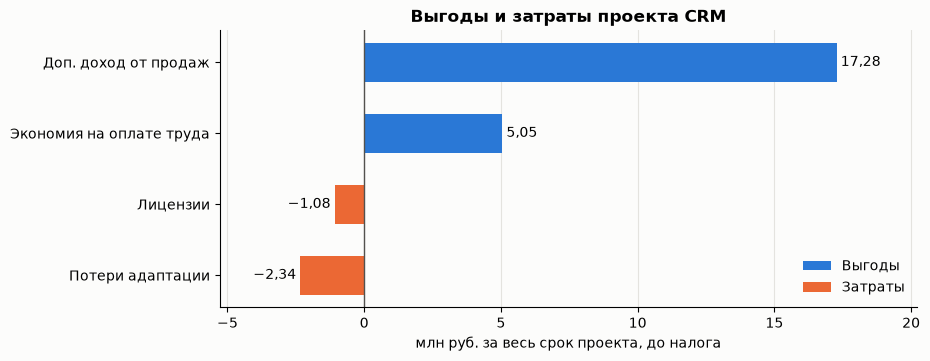

In [12]:
# График 1. Из чего складывается результат за весь срок (до налога)
parts = pd.Series({
    "Доп. доход от продаж": res["sales_flow"].sum(),
    "Экономия на оплате труда": res["saving_flow"].sum(),
    "Лицензии": -res["license_flow"].sum(),
    "Потери адаптации": -res["adaptation_flow"].sum(),
}) / MLN
gains, losses = parts[parts > 0], parts[parts <= 0]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(gains.index, gains.values, color=BLUE, height=0.55, label="Выгоды")
ax.barh(losses.index, losses.values, color=ORANGE, height=0.55, label="Затраты")
# Подписываем значение рядом с каждым столбцом
for name, value in parts.items():
    ax.text(value, name, f" {fmt(value, 2)} ", va="center",
            ha="left" if value > 0 else "right")
ax.invert_yaxis()                          # первая строка сверху
ax.margins(x=0.15)                         # место для подписей
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlabel("млн руб. за весь срок проекта, до налога")
ax.set_title("Выгоды и затраты проекта CRM")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(os.path.join(FIG_DIR, "01_components.png"), dpi=160, bbox_inches="tight")
plt.show()

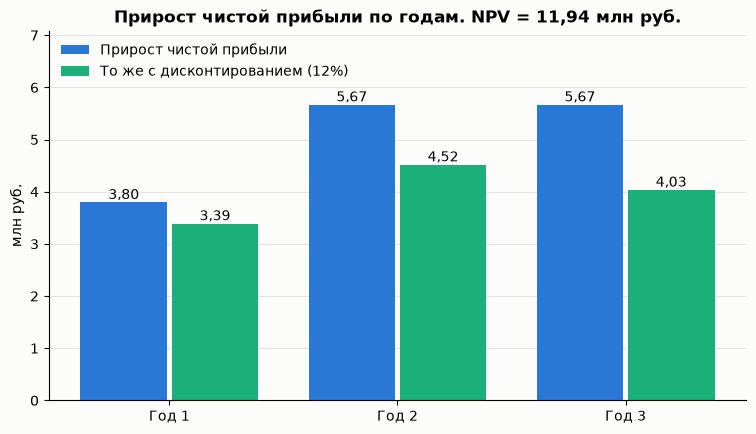

In [13]:
# График 2. Прирост чистой прибыли по годам: обычный и дисконтированный
x = np.arange(len(res["years"]))
fig, ax = plt.subplots()
bars_net = ax.bar(x - 0.2, res["net_profit"] / MLN, width=0.38, color=BLUE,
                  label="Прирост чистой прибыли")
bars_disc = ax.bar(x + 0.2, res["discounted"] / MLN, width=0.38, color=GREEN,
                   label=f"То же с дисконтированием ({pct(BASE['rate'])})")
# Подписываем значения над столбцами
for bar in list(bars_net) + list(bars_disc):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            fmt(bar.get_height(), 2), ha="center", va="bottom")
ax.set_xticks(x, [f"Год {t}" for t in res["years"]])
ax.margins(y=0.25)                         # место для легенды и подписей
ax.set_ylabel("млн руб.")
ax.set_title(f"Прирост чистой прибыли по годам. NPV = {fmt(res['npv'] / MLN, 2)} млн руб.")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.savefig(os.path.join(FIG_DIR, "01_net_profit.png"), dpi=160, bbox_inches="tight")
plt.show()

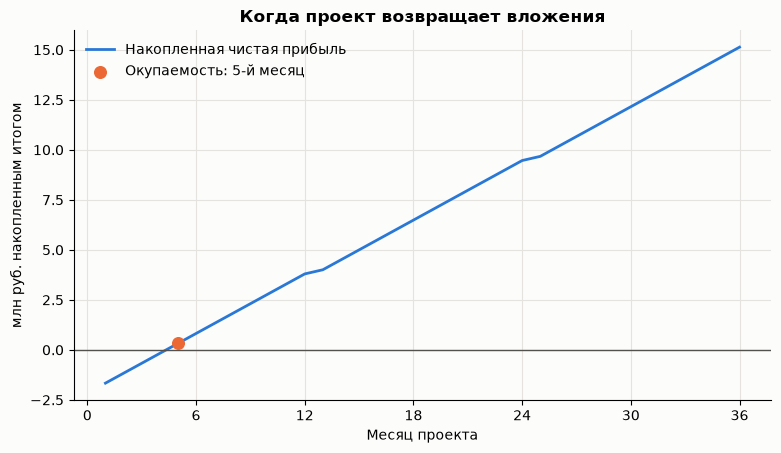

In [14]:
# График 3. Накопленная чистая прибыль по месяцам и точка окупаемости
fig, ax = plt.subplots()
ax.plot(months, cumulative / MLN, color=BLUE, linewidth=2,
        label="Накопленная чистая прибыль")
ax.axhline(0, color=GRAY, linewidth=1)
# Точка окупаемости (если проект окупается за горизонт)
if payback_month:
    ax.scatter([payback_month], [cumulative[payback_month - 1] / MLN], color=ORANGE,
               s=70, zorder=3, label=f"Окупаемость: {payback_month}-й месяц")
ax.set_xticks(range(0, len(months) + 1, 6))
ax.set_xlabel("Месяц проекта")
ax.set_ylabel("млн руб. накопленным итогом")
ax.set_title("Когда проект возвращает вложения")
ax.legend(frameon=False, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "01_payback.png"), dpi=160, bbox_inches="tight")
plt.show()

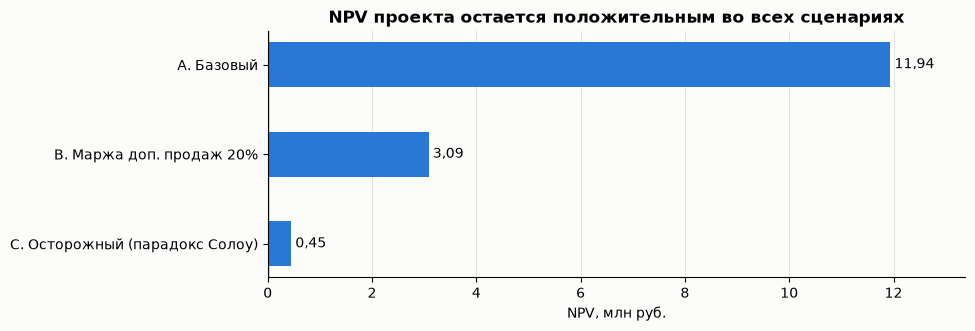

In [15]:
# График 4. NPV по сценариям
scenario_npv = scenario_table["NPV, млн руб."]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(scenario_npv.index, scenario_npv.values, color=BLUE, height=0.5)
# Подписываем значение рядом с каждым столбцом
for name, value in scenario_npv.items():
    ax.text(value, name, f" {fmt(value, 2)}", va="center")
ax.invert_yaxis()                          # базовый сценарий сверху
ax.margins(x=0.12)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlabel("NPV, млн руб.")
ax.set_title("NPV проекта остается положительным во всех сценариях")
ax.grid(axis="y", visible=False)
fig.savefig(os.path.join(FIG_DIR, "01_scenarios.png"), dpi=160, bbox_inches="tight")
plt.show()

In [16]:
# Сохраняем главные показатели в файл reports/01_summary.json
summary = {
    "saving_year": res["saving"],
    "extra_sales_year": res["extra_sales"],
    "licenses_total": licenses_total,
    "adaptation_loss": res["adaptation_loss"],
    "costs_total": costs_total,
    "net_profit_by_year": res["net_profit"].tolist(),
    "npv": res["npv"],
    "roi": res["roi"],
    "roi_net": res["roi_net"],
    "payback_month": payback_month,
    "payback_formula_months": payback_formula,
    "npv_by_scenario": {name: s["npv"] for name, s in scenarios.items()},
    "npv_lost_sales_adaptation": lost_sales["npv"],
}
with open(os.path.join("..", "reports", "01_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Показатели сохранены в reports/01_summary.json")

Показатели сохранены в reports/01_summary.json


## 3. Анализ результатов

### 3.1. Интерпретация полученных данных

- **Основной эффект дают продажи.** CRM приносит 7,44 млн руб. в год: 5,76 млн руб. (77%) — рост продаж и 1,68 млн руб.
  (23%) — экономия времени. Экономия 6% времени — это 0,9 ставки менеджера. Уволить «девять десятых человека» нельзя,
  поэтому деньгами эта экономия станет, только если менеджеры потратят освободившееся время на продажи.
- **Затраты небольшие.** За 3 года проект стоит 3,42 млн руб.: 1,08 млн руб. лицензии и 2,34 млн руб. потери адаптации.
  Больше двух третей затрат (68,4%) — это не плата поставщику, а время на обучение. Для ИТ-проектов это типично:
  цена лицензии — меньшая часть настоящей стоимости.
- **Проект выгоден по всем показателям.** NPV = 11,94 млн руб. (больше нуля), ROI = 553% до налога и 442% по чистой
  прибыли, вложения возвращаются на 5-м месяце.
- **Вывод устойчив, но запас бывает мал.** NPV остается положительным и при марже 20% (3,09 млн руб.), и в осторожном
  сценарии (0,45 млн руб.). Но в осторожном сценарии от базовых 11,94 млн руб. остается около 4%.

### 3.2. Сравнение с альтернативными вариантами

- **«Не внедрять».** Эта альтернатива дает NPV = 0 и проигрывает проекту во всех трех сценариях.
- **Другая трактовка роста продаж.** Если 8% накапливаются год к году, прибавка в 3-й год была бы 18,7 млн руб. вместо
  5,76. В расчете взят осторожный вариант, поэтому при другой трактовке вывод только усилится.
- **Маржа.** Самое сильное условие расчета — что вся дополнительная выручка становится прибылью. При марже 20% NPV падает
  с 11,94 до 3,09 млн руб., ROI — с 553% до 149%. Проект остается выгодным, но уже не «сверхдоходным».
- **Другая оценка потерь адаптации.** Если считать, что за месяц обучения потерян месячный оборот (6 млн руб.),
  а не оплата труда отдела, NPV снижается до 9,33 млн руб. и остается положительным.

### 3.3. Нематериальные эффекты, парадокс Солоу и связь с теорией (задание 4)

**Нематериальные выгоды CRM, которых нет в расчете:**

1. *Клиентская база принадлежит компании, а не менеджеру.* Сотрудник уволился — контакты и история сделок остались.
2. *Прозрачная воронка продаж.* Руководитель видит, на каком этапе теряются сделки; прогноз выручки точнее.
3. *Качество обслуживания.* Меньше забытых звонков и потерянных заявок, клиенты остаются дольше.
4. *Данные для анализа.* Можно сравнивать каналы продаж, сегменты клиентов и работу менеджеров.
5. *Быстрый ввод новичков* за счет единого порядка работы со сделками.
6. *Ниже транзакционные издержки* внутри компании: меньше согласований, отчеты формируются сами.

**Как парадокс Солоу может изменить фактический результат.** Парадокс производительности («компьютерный век виден
везде, кроме статистики производительности труда») означает, что реальный эффект от ИТ часто меньше расчетного или
приходит позже:

- *задержка эффекта:* в условии на адаптацию дан 1 месяц, на практике освоение CRM часто занимает несколько месяцев;
- *нужны изменения в работе:* без регламента и привязки мотивации CRM превращается в «дорогую записную книжку»;
- *экономия времени не равна экономии денег:* зарплаты не уменьшатся, эффект будет только при переносе времени на продажи;
- *эффект трудно измерить:* рост продаж на 8% сложно отделить от влияния рынка, сезона и рекламы.

Сценарий C показывает эту поправку в цифрах: NPV падает с 11,94 до 0,45 млн руб., то есть в 26 раз, но остается
положительным.

**Связь с другими понятиями лекции №1.**

- *Свойства информационных благ.* Облачная CRM — информационное благо: создать ее дорого, а подключить еще одного
  пользователя поставщику почти ничего не стоит (предельные затраты стремятся к нулю, эффект масштаба). Поэтому цена
  лицензии определяется не затратами поставщика, а ценностью для покупателя. По расчету один менеджер с CRM приносит
  около 496 тыс. руб. эффекта в год — почти в 21 раз больше цены лицензии (24 тыс. руб.).
- *Неконкурентность.* Клиентская база в CRM — тоже информационное благо: ею одновременно пользуются все менеджеры
  и руководитель, и от этого ее не становится меньше.
- *Неопределенность ценности.* Пользу CRM нельзя точно узнать до внедрения («не знаю, пока не получу»). Поэтому
  рост продаж на 8% — прогноз, а не факт, и до покупки на всех нужен пилот.
- *Информационная асимметрия.* Поставщик знает о системе больше покупателя (скрытые характеристики), поэтому нужны
  пробный период и пилот. Менеджер знает о своих клиентах больше, чем компания (скрытые действия), и CRM эту
  асимметрию уменьшает: работа с клиентом становится видна руководителю.

## 4. Выводы и рекомендации

### 4.1. Ключевые выводы

1. Внедрять облачную CRM выгодно: NPV = **11,94 млн руб.**, ROI = **553%** (442% по чистой прибыли), окупаемость —
   на **5-м месяце**.
2. Прирост чистой прибыли: **3,80 млн руб.** в 1-й год и по **5,67 млн руб.** во 2-й и 3-й годы, всего 15,13 млн руб.
3. 77% эффекта дает рост продаж. Одна экономия времени за 3 года (5,05 млн руб.) покрывает затраты
   (3,42 млн руб.) с небольшим запасом, поэтому главное — чтобы продажи действительно выросли.
4. Вывод сохраняется в осторожных сценариях, но размер эффекта сильно зависит от маржи дополнительных продаж
   и от того, вырастут ли продажи на самом деле.

### 4.2. Практические рекомендации

1. **Внедрять CRM.** Решение выгодно даже в осторожном сценарии, а подписка не требует крупных вложений на старте,
   и от нее можно отказаться с малыми потерями.
2. **Управлять ростом продаж, а не ценой лицензии.** Заранее решить, на что менеджеры потратят освободившиеся 6%
   времени (дополнительные звонки, работа с «холодной» базой), и закрепить это в KPI.
3. **Сократить потери адаптации** — это 68,4% затрат: обучать группами, начать с пилота на 3–5 менеджерах,
   не внедрять в сезон пиковых продаж.
4. **Менять порядок работы вместе с системой:** регламент ведения сделок и привязка мотивации к работе в CRM.
   Это главный способ не попасть под парадокс Солоу.
5. **Измерять фактический эффект:** записать показатели до внедрения (конверсия, длительность сделки, выручка
   на менеджера), сравнить через 6 и 12 месяцев и пересмотреть решение, если продажи не растут.